<a href="https://colab.research.google.com/github/YASHRNN13/Road-Accidents/blob/main/Road%20Accidents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving morth_road_accidents_weather.csv to morth_road_accidents_weather.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

df = pd.read_csv('morth_road_accidents_weather.csv')

print("Dataset Shape:", df.shape)
print("\nColumn Names:", list(df.columns))
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (6390, 7)

Column Names: ['year', 'state', 'city', 'type_of_weather_condition', 'category', 'value', 'unit']

First 5 rows:


,year,state,city,type_of_weather_condition,category,value,unit
0,2022,Andaman and Nicobar Islands,Patna,Sunny or Clear,Killed,32,value in absolute number
1,2021,Karnataka,Chennai,Sunny or Clear,Grievously Injured,47,value in absolute number
2,2022,Rajasthan,Mumbai,Sunny or Clear,Killed,29,value in absolute number
3,2021,West Bengal,Surat,Sunny or Clear,Grievously Injured,38,value in absolute number
4,2019,Assam,Kolkata,Sunny or Clear,Killed,29,value in absolute number


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6390 entries, 0 to 6389
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   year                       6390 non-null   int64 
 1   state                      6390 non-null   object
 2   city                       6294 non-null   object
 3   type_of_weather_condition  6390 non-null   object
 4   category                   6390 non-null   object
 5   value                      6390 non-null   int64 
 6   unit                       6390 non-null   object
dtypes: int64(2), object(5)
memory usage: 349.6+ KB


In [ ]:

print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print(f"Percentage missing: {(df.isnull().sum().sum()/df.size)*100:.2f}%")

year                          0
state                         0
city                         96
type_of_weather_condition     0
category                      0
value                         0
unit                          0
dtype: int64

Total missing values: 96
Percentage missing: 0.21%


In [ ]:

dup_count = df.duplicated().sum()
print(f"Number of duplicate rows found: {dup_count}")

df['city'] = df['city'].fillna('Unknown')
df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"\nShape before cleaning: {df.shape}")
print(f"Shape after removing duplicates: {df_clean.shape}")
df = df_clean.copy()

Number of duplicate rows found: 44

Shape before cleaning: (6390, 7)
Shape after removing duplicates: (6346, 7)


In [ ]:

le_weather = LabelEncoder()
le_category = LabelEncoder()
le_state = LabelEncoder()

df['weather_encoded'] = le_weather.fit_transform(df['type_of_weather_condition'])
df['category_encoded'] = le_category.fit_transform(df['category'])
df['state_encoded'] = le_state.fit_transform(df['state'])

print("Weather condition mapping:")
for i, label in enumerate(le_weather.classes_):
    print(f"  {label} -> {i}")

df[['type_of_weather_condition','weather_encoded','category','category_encoded']].head(8)

Weather condition mapping:
  Cloudy -> 0
  Dust Storm -> 1
  Foggy or Misty -> 2
  Hail or Sleet -> 3
  Others -> 4
  Rainy -> 5
  Snowfall -> 6
  Strong Wind -> 7
  Sunny or Clear -> 8


,type_of_weather_condition,weather_encoded,category,category_encoded
0,Sunny or Clear,8,Killed,2
1,Sunny or Clear,8,Grievously Injured,1
2,Sunny or Clear,8,Killed,2
3,Sunny or Clear,8,Grievously Injured,1
4,Sunny or Clear,8,Killed,2
5,Sunny or Clear,8,Persons Injured,4
6,Sunny or Clear,8,Accidents,0
7,Sunny or Clear,8,Killed,2


In [ ]:

dist = df['type_of_weather_condition'].value_counts()
dist_pct = df['type_of_weather_condition'].value_counts(normalize=True) * 100
result = pd.DataFrame({'Count': dist, 'Percentage': dist_pct.round(2)})
print(result)
print(f"\n=> Sunny/Clear alone accounts for {dist_pct['Sunny or Clear']:.1f}% of all records")
print("=> This confirms severe class imbalance")

                           Count  Percentage
type_of_weather_condition                   
Sunny or Clear              4686       73.84
Rainy                        659       10.38
Foggy or Misty               316        4.98
Cloudy                       240        3.78
Dust Storm                   139        2.19
Others                       120        1.89
Hail or Sleet                 69        1.09
Strong Wind                   61        0.96
Snowfall                      56        0.88

=> Sunny/Clear alone accounts for 73.8% of all records
=> This confirms severe class imbalance


In [ ]:

X = df[['year','state_encoded','category_encoded','value']]
y = df['weather_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Full dataset size: {len(df)}")
print(f"Training set size: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing set size: {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

Full dataset size: 6346
Training set size: 5076 (80.0%)
Testing set size: 1270 (20.0%)


/tmp/ipykernel_452/2571769403.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='type_of_weather_condition', order=order, palette='viridis')


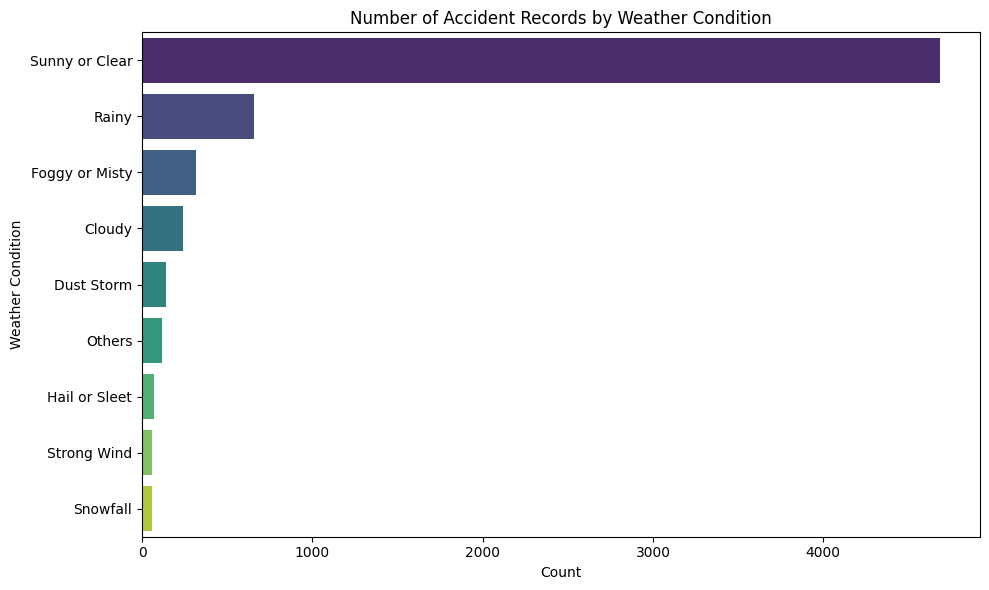

In [ ]:

plt.figure(figsize=(10,6))
order = df['type_of_weather_condition'].value_counts().index
sns.countplot(data=df, y='type_of_weather_condition', order=order, palette='viridis')
plt.title('Number of Accident Records by Weather Condition')
plt.xlabel('Count')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.show()

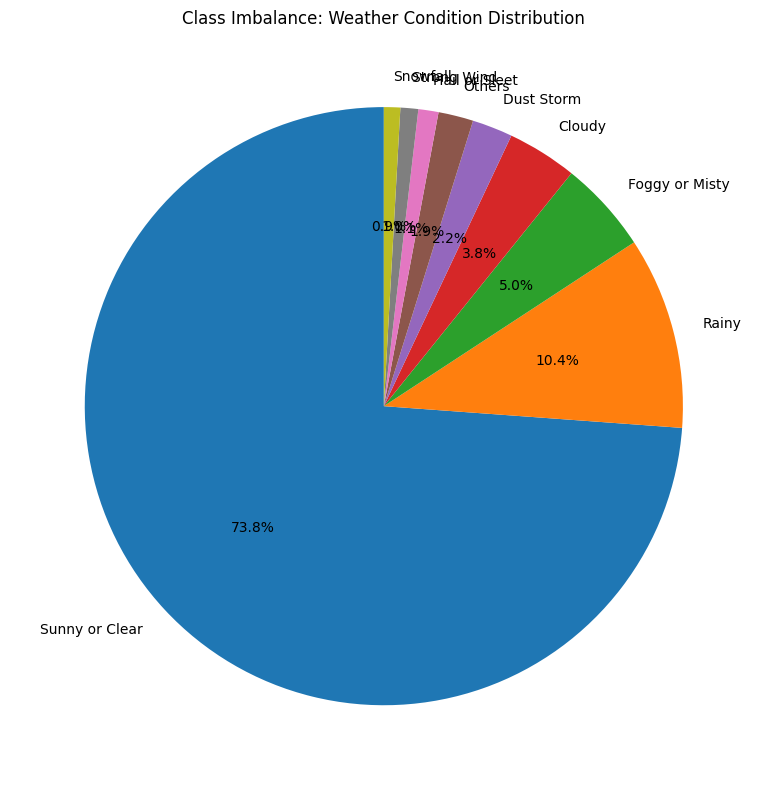

In [ ]:

plt.figure(figsize=(8,8))
weather_counts = df['type_of_weather_condition'].value_counts()
plt.pie(weather_counts, labels=weather_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Class Imbalance: Weather Condition Distribution')
plt.tight_layout()
plt.show()

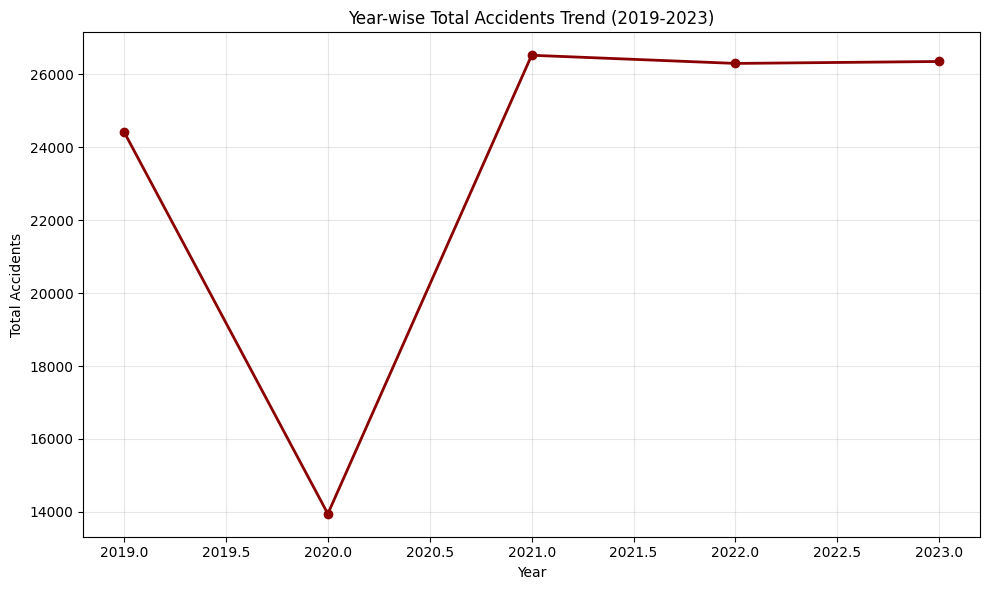

In [ ]:

plt.figure(figsize=(10,6))
yearly = df[df['category']=='Accidents'].groupby('year')['value'].sum()
plt.plot(yearly.index, yearly.values, marker='o', linewidth=2, color='darkred')
plt.title('Year-wise Total Accidents Trend (2019-2023)')
plt.xlabel('Year')
plt.ylabel('Total Accidents')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_452/2622224737.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_states.values, y=top_states.index, palette='mako')


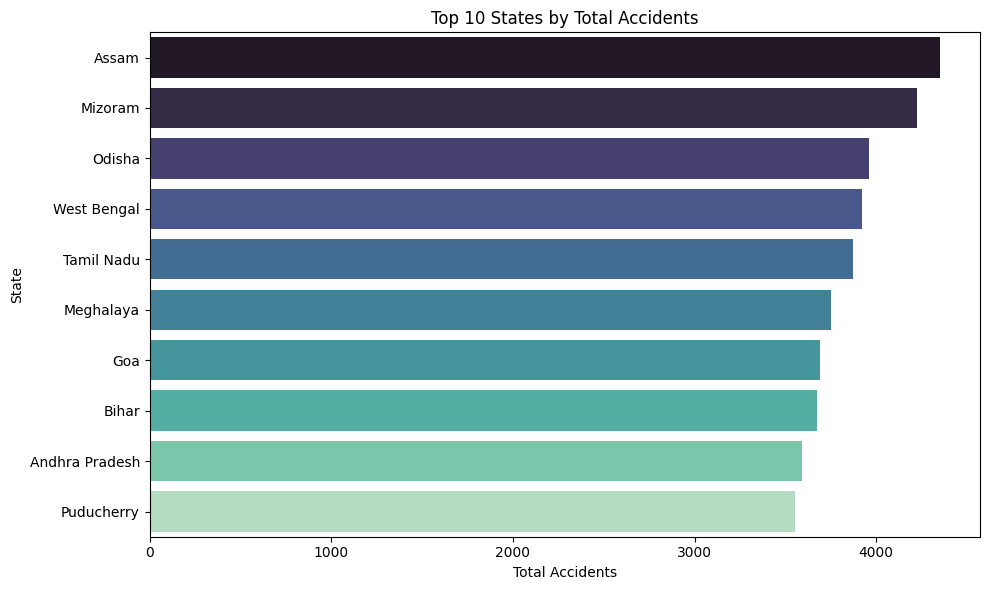

In [ ]:
plt.figure(figsize=(10,6))
top_states = df[df['category']=='Accidents'].groupby('state')['value'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_states.values, y=top_states.index, palette='mako')
plt.title('Top 10 States by Total Accidents')
plt.xlabel('Total Accidents')
plt.ylabel('State')
plt.tight_layout()
plt.show()

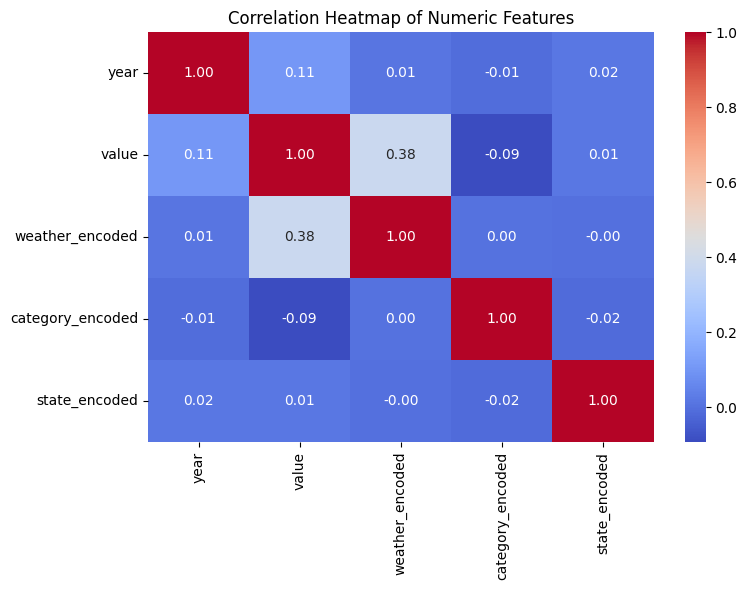

In [ ]:
plt.figure(figsize=(8,6))
numeric_df = df[['year','value','weather_encoded','category_encoded','state_encoded']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()